# 以 PCA 主軸分出牙冠與牙根（臨床冠根比）

依你手寫的 Algorithm：

1. AI 模型提供牙齒 mask 的邊界點集合 `B = {x, y}`，可求出**質心 `C′`**
2. 給定 `B`，做 PCA 得第一主軸 **`L`**
3. `L ∩ M = (x₀, y₀)` → **`O` 點**（`M` 為左右兩側齒槽骨頂 `D`、`C` 的連線）
4. 由與主軸**投影最長**的點找 `A`、`B`（牙冠／牙根基準點）：
   `A = max(Bᵢ·C′ ⃗ · L ⃗)`（在 `C′` 上方）、`B = max(Bᵢ·C′ ⃗ · L ⃗)`（在 `C′` 下方）
5. 由**多參數加權**決定 `C`、`D`
6. 牙冠長 `|AO|`、牙根長 `|BO|`，**CRR = |AO| / |BO|**

草圖中的綠線 `G` ＝ 人工標註的齒槽骨線，`θ` ＝ 演算法 `CD` 與 `G` 的夾角。

**實作對應**（`src/segmentation/alveolar.py`）

| 步驟 | 實作 |
|---|---|
| 1–2 | `tooth_axis`：質心與 PCA；方向統一為牙冠 → 牙根（較窄端為牙根） |
| 4 | 本筆記本用 `end_percentile=0`：`A`、`B` ＝ 邊界點對主軸投影的**最大／最小值**（演算法預設為 1%／99% 以抗 mask 雜訊） |
| 5 | `pair_mode="weighted"`：每側取階梯分數的前 K 個候選，對 `(D, C)` 配對，以 **階梯強度、等高、左右對稱、與軸夾角、解剖位置** 五項加權（權重為預設值，尚未調參） |
| 3、6 | `O` ＝ `CD` 與 `L` 的交點；CRR ＝ `|AO| / |OB|` |

**限制**：沒有醫師真值前只是候選位置。調參只看 val；你標註的 test 只做一次性評估（見第 4 節的旗標）。

In [12]:
import csv, json, sys
from pathlib import Path
from collections import Counter

ROOT = next(d for d in (Path.cwd(), *Path.cwd().parents) if (d / "data/derived").is_dir())
sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np

from src.segmentation.alveolar import (AlveolarConfig, load_crop, locate_alveolar_crest, tooth_axis,
                                       scan_profile, reference_from_points, compare_with_reference)

plt.rcParams["font.sans-serif"] = ["Noto Sans CJK TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

DERIVED = sorted((ROOT / "data/derived").glob("roi_*"))[-1]
SEG_ROOT = ROOT / "data/seg_dataset"
# CFG = AlveolarConfig(end_percentile=0.0, pair_mode="weighted")   # 依你的演算法：A、B 取最大投影；C、D 取加權配對
ROWS = {r["roi_id"]: r for r in json.loads((DERIVED / "roi_index.json").read_text())}
ANN_PATH = ROOT / f"data/cej_annotations/cej_{DERIVED.name}.json"
ANN = json.loads(ANN_PATH.read_text())["teeth"] if ANN_PATH.exists() else {}
ANN = {k: v for k, v in ANN.items() if v["status"] == "annotated" and k in ROWS}

VAL_IDS = sorted(k for k, r in ROWS.items() if r["subset"] == "val")
ROI_ID = VAL_IDS[0]                                 # 預設看 val 的第一顆；可改成任何 roi_id
EVALUATE_ON_TEST = True                           # True = 對已標註的 test 牙做「一次性」最終評估（之後不可再依結果調參）
POINTS_FROM = "algorithm"                            # "algorithm"（演算法找骨頂）或 "annotation"（用你標的兩點）
print(DERIVED.name, "| ROI:", ROI_ID, "| annotated teeth:", len(ANN))

roi_2a0c9441396f | ROI: 109_00 | annotated teeth: 46


## 1. PCA 主軸：`L`、`A`、`B`

質心 C' = (353.4, 1277.7) | A、B 取對主軸投影的極端百分位
軸長 |AB| = 1552.0 px | 拉長比 λ1/λ2 = 13.49 | 兩端寬度比 = 0.46
warnings: none


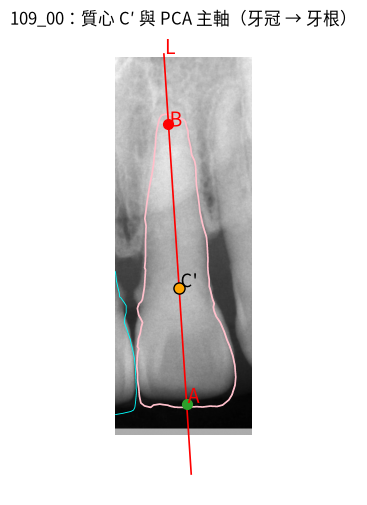

In [13]:
row = ROWS[ROI_ID]
crop = load_crop(row, SEG_ROOT)
mask = crop["mask"]
ax = tooth_axis(mask, CFG)
c, v, u = ax["origin"], ax["v"], ax["u"]
A = c + v * ax["t_top"]
B = c + v * ax["t_bot"]
print(f"質心 C' = ({c[0]:.1f}, {c[1]:.1f}) | A、B 取對主軸投影的{'最大／最小值' if CFG.end_percentile == 0 else '極端百分位'}")
print(f"軸長 |AB| = {ax['length']:.1f} px | 拉長比 λ1/λ2 = {ax['elongation']:.2f} | 兩端寬度比 = {ax['width_ratio']:.2f}")
print("warnings:", ax["warnings"] or "none")


def draw_axis(a, ext=0.25):
    ys, xs = np.nonzero(mask)
    a.imshow(crop["gray"], cmap="gray")
    a.contour(mask, [0.5], colors="pink", linewidths=1.2)
    a.contour(crop["others"], [0.5], colors="cyan", linewidths=0.6)
    p0, p1 = A - v * ax["length"] * ext, B + v * ax["length"] * ext
    a.plot([p0[0], p1[0]], [p0[1], p1[1]], "r-", lw=1.2)
    a.plot(*c, "o", color="orange", ms=8, mec="k"); a.text(c[0] + 8, c[1] - 6, "C'", color="k", fontsize=13)
    a.plot(*A, "o", color="tab:green", ms=7); a.text(A[0] + 6, A[1] - 6, "A", color="r", fontsize=14)
    a.plot(*B, "o", color="r", ms=7); a.text(B[0] + 6, B[1] + 14, "B", color="r", fontsize=14)
    a.text(p1[0] + 6, p1[1], "L", color="r", fontsize=14)
    a.axis("off")


fig, a = plt.subplots(figsize=(5, 6)); draw_axis(a); a.set_title(f"{ROI_ID}：質心 C′ 與 PCA 主軸（牙冠 → 牙根）"); plt.show()

## 2. 垂直於 `L` 的掃描線（草圖中的綠色箭頭）

在 `A` 到 `B` 之間每個高度做一條垂直掃描線，量**軸到左／右輪廓的距離**。冠部較寬、根部較窄；分叉牙（臼齒）會在根部出現寬度驟降。

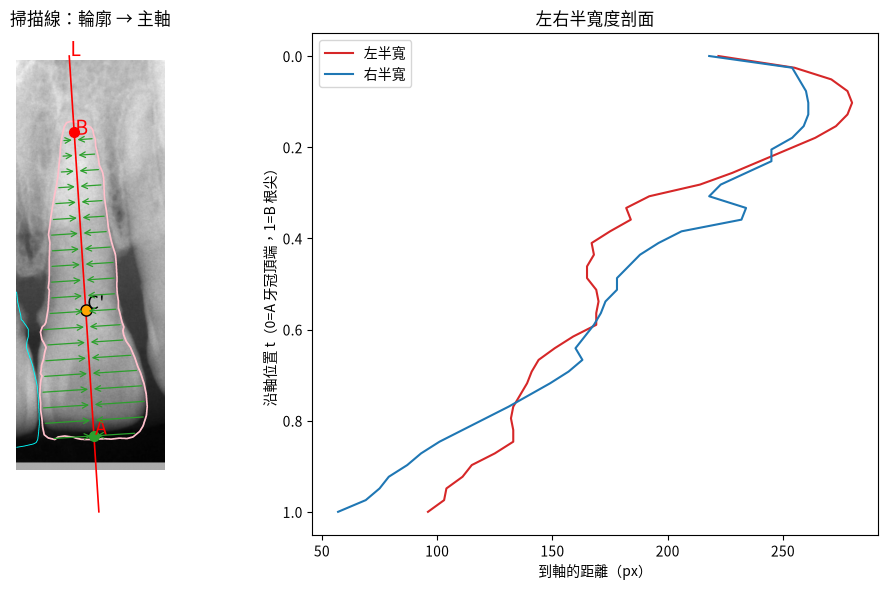

In [14]:
sp = scan_profile(mask, ax, CFG, n_levels=40)
fig, axs = plt.subplots(1, 2, figsize=(11, 6), gridspec_kw={"width_ratios": [1, 1]})
draw_axis(axs[0])
for lp, rp, ft in list(zip(sp["left_pts"], sp["right_pts"], sp["feet"]))[::2]:
    for p in (lp, rp):
        axs[0].annotate("", xy=ft, xytext=p, arrowprops=dict(arrowstyle="->", color="tab:green", lw=0.9))
axs[0].set_title("掃描線：輪廓 → 主軸")
axs[1].plot(sp["left_dist"], sp["t_frac"], "tab:red", label="左半寬")
axs[1].plot(sp["right_dist"], sp["t_frac"], "tab:blue", label="右半寬")
axs[1].invert_yaxis(); axs[1].set_ylabel("沿軸位置 t（0=A 牙冠頂端，1=B 根尖）"); axs[1].set_xlabel("到軸的距離（px）")
axs[1].legend(); axs[1].set_title("左右半寬度剖面")
plt.tight_layout(); plt.show()

## 3. 兩側參考點 `C`、`D`、交點 `O`、牙冠／牙根

`POINTS_FROM="algorithm"`：用 `locate_alveolar_crest` 在對比增強影像上找左右齒槽骨頂；
`"annotation"`：直接用你用 `annotate_cej.py` 標的兩點。不論哪種，`O` 都是兩點連線與 PCA 主軸的交點。

標籤 `D`、`C` 依「牙冠朝上」的牙齒座標系定義（`D` 在左、`C` 在右）；上顎牙在影像裡牙冠朝下，所以畫面上 `D` 會出現在右邊。

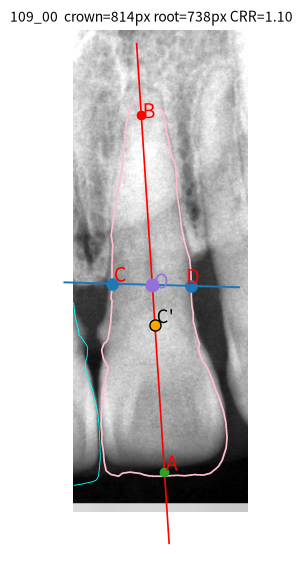

warnings: none


In [15]:
def frame_to_crop(res, x, y):
    inv = cv2.invertAffineTransform(res["frame"]["M"])
    return (inv @ np.array([x, y, 1.0])).tolist()


def ext_line(p0, p1, k=0.6):
    p0, p1 = np.array(p0, float), np.array(p1, float)
    d = p1 - p0
    return p0 - d * k, p1 + d * k


def analyse(row_id, points_from=POINTS_FROM, cfg=CFG, draw=True):
    row = ROWS[row_id]
    cr = load_crop(row, SEG_ROOT)
    trunc = bool(row["target_truncated_by_roi"] or row["truncated_at_source"])
    res = locate_alveolar_crest(cr["gray"], cr["mask"], cr["valid"], cr["others"], cfg, truncated=trunc)
    gt = None
    if row_id in ANN:
        x0, y0 = row["expanded_xyxy"][:2]
        gt_crop = [[x - x0, y - y0] for x, y in ANN[row_id]["points_original"]]
        gt = reference_from_points(res, gt_crop, cfg)
    out = {"roi_id": row_id, "warnings": res["warnings"]}
    if points_from == "annotation":
        if gt is None:
            raise ValueError(f"{row_id} 沒有標註")
        pts = sorted(gt_crop, key=lambda p: p[0]); out.update(crown_px=gt["crown_px"], root_px=gt["root_px"], crr=gt["crr"])
        O = frame_to_crop(res, res["frame"]["xc"], gt["yO"])
    else:
        pts = [res["crest_crop"][s] for s in ("left", "right") if s in res.get("crest_crop", {})]
        O = res.get("O_crop")
        out.update(crown_px=res.get("crown_px"), root_px=res.get("root_px"), crr=res.get("crr"))
    if draw:
        fig, a = plt.subplots(figsize=(6, 7))
        a.imshow(res.get("contrast", cr["gray"]), cmap="gray")
        a.contour(cr["mask"], [0.5], colors="pink", linewidths=1.2)
        a.contour(cr["others"], [0.5], colors="cyan", linewidths=0.6)
        ax_ = res["axis"]
        A_, B_ = res["A_crop"] if "A_crop" in res else None, res["B_crop"] if "B_crop" in res else None
        if A_ is not None:
            p0, p1 = ext_line(A_, B_, 0.2)
            a.plot([p0[0], p1[0]], [p0[1], p1[1]], "r-", lw=1.2)
            a.plot(*A_, "o", color="tab:green"); a.text(A_[0] + 6, A_[1] - 6, "A", color="r", fontsize=14)
            a.plot(*B_, "ro"); a.text(B_[0] + 6, B_[1] + 14, "B", color="r", fontsize=14)
        if len(pts) == 2:
            q0, q1 = ext_line(pts[0], pts[1])
            a.plot([q0[0], q1[0]], [q0[1], q1[1]], color="tab:blue", lw=1.4)
            a.plot(*pts[0], "o", color="tab:blue", ms=8); a.text(pts[0][0] - 22, pts[0][1] - 8, "D", color="r", fontsize=14)
            a.plot(*pts[1], "o", color="tab:blue", ms=8); a.text(pts[1][0] + 8, pts[1][1] - 8, "C", color="r", fontsize=14)
        a.plot(*res["axis"]["origin"], "o", color="orange", ms=8, mec="k"); a.text(res["axis"]["origin"][0] + 8, res["axis"]["origin"][1] - 6, "C'", fontsize=13)
        if O is not None:
            a.plot(*O, "o", color="mediumpurple", ms=9); a.text(O[0] + 8, O[1] + 16, "O", color="mediumpurple", fontsize=14)
        if gt is not None and points_from == "algorithm":
            g0, g1 = ext_line(*sorted(gt_crop, key=lambda p: p[0]))
            a.plot([g0[0], g1[0]], [g0[1], g1[1]], color="lime", lw=1.4); a.text(g0[0], g0[1] - 6, "G", color="lime", fontsize=14)
        cmp_ = compare_with_reference(res, gt) if gt is not None else {}
        ang = cmp_.get("line_angle_deg")
        title = f"{row_id}  crown={out['crown_px'] or float('nan'):.0f}px root={out['root_px'] or float('nan'):.0f}px CRR={out['crr'] or float('nan'):.2f}"
        if ang is not None:
            title += f"  θ={ang:.1f}°  cos={cmp_['line_cosine']:.3f}"
        if res.get("pair"):
            title += f"  pair={res['pair']['score']:.2f}"
        a.set_title(title, fontsize=10); a.axis("off"); plt.show()
        print("warnings:", res["warnings"] or "none")
    out["cmp"] = compare_with_reference(res, gt) if gt is not None and "O_frame" in res else {}
    return out


_ = analyse(ROI_ID)

## 4. 標註過的牙齒整批計算：演算法 vs 標註

In [16]:
def batch_ids():
    ids = list(ANN)
    sub = Counter(ROWS[i]["subset"] for i in ids)
    print("標註涵蓋的子集：", dict(sub))
    if not EVALUATE_ON_TEST:
        ids = [i for i in ids if ROWS[i]["subset"] != "test"]
        if not ids:
            print("目前標註都在 test。為保持 test 獨立，預設不評估；請先標註 val，或把 EVALUATE_ON_TEST 設為 True 做一次性最終評估。")
    else:
        print("注意：EVALUATE_ON_TEST=True，這是對 test 的最終評估，請不要再依結果調參。")
    return ids


rows_out = []
for rid in batch_ids():
    a = analyse(rid, "algorithm", draw=False)
    g = analyse(rid, "annotation", draw=False)
    rows_out.append({"roi_id": rid, "crr_algo": a["crr"], "crr_annot": g["crr"], "crown_algo": a["crown_px"],
                     "crown_annot": g["crown_px"], "root_algo": a["root_px"], "root_annot": g["root_px"],
                     "theta_deg": a["cmp"].get("line_angle_deg"), "cosine": a["cmp"].get("line_cosine"),
                     "warnings": ";".join(a["warnings"])})
print(len(rows_out), "teeth")
both = [r for r in rows_out if r["crr_algo"] is not None]
if both:
    d = np.array([r["crr_algo"] - r["crr_annot"] for r in both])
    print(f"CRR 差（演算法−標註）n={len(d)} median={np.median(d):+.2f} mean={d.mean():+.2f} MAE={np.abs(d).mean():.2f}")
th = np.array([r["theta_deg"] for r in rows_out if r["theta_deg"] is not None])
if len(th):
    print(f"θ n={len(th)} median={np.median(th):.1f}° p90={np.percentile(th, 90):.1f}°")
OUT = ROOT / "reports/segmentation/alveolar"; OUT.mkdir(parents=True, exist_ok=True)
if rows_out:
    with open(OUT / f"{DERIVED.name}_crown_root_vs_annotation.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows_out[0])); w.writeheader(); w.writerows(rows_out)

標註涵蓋的子集： {'test': 46}
注意：EVALUATE_ON_TEST=True，這是對 test 的最終評估，請不要再依結果調參。
46 teeth
CRR 差（演算法−標註）n=36 median=+0.08 mean=+0.09 MAE=0.49
θ n=26 median=3.8° p90=11.8°
